<a href="https://colab.research.google.com/github/BaDoingleZoinks/TXST-TECH4397-WaterQuality-ML/blob/main/notebooks/Copy_of_Assignment_9_Starter_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TECH 4397: Assignment 9 — System-Level Synthesis & Failure-Mode Attribution
### Decoupling Hardware Decay, Environmental Matrix Effects, and Machine Learning Limits

**Welcome!** This starter notebook is completely self-contained. You do **not** need to write machine-learning pipelines from scratch.

**Instructions:**
1. Click **File -> Save a copy in Drive**.
2. Execute the code cells in order from **Step 1** to **Step 5** using the **Play button (▶)**.
3. Copy the generated error statistics tables, model confidence audit, and plots into your report to answer the synthesis questions.

---
## STEP 1: Train the Dual Pipeline (Full 7-Feature vs DO-Free 5-Feature Model)
**Action:** Click the **Play button (▶)** below to load the baseline steady-state chemical dataset ($n=79$) and train both models.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, SVR
from sklearn.metrics import accuracy_score, r2_score, mean_squared_error

# 1. Load canonical single-chemical training data matching thesis Tables 3-1, 4-1, and 7-2
np.random.seed(42)
chems = (
    ['Sodium Bicarbonate'] * 21 +
    ['Calcium Carbonate'] * 17 +
    ['Sodium Chloride'] * 16 +
    ['Hydrogen Peroxide'] * 14 +
    ['Magnesium'] * 11
)

doses = np.concatenate([
    np.linspace(0.01, 0.60, 21),   # NaHCO3 (g)
    np.linspace(0.01, 0.40, 17),   # CaCO3 (g)
    np.linspace(0.01, 0.225, 16),  # NaCl (g)
    np.linspace(1.0, 26.0, 14),    # H2O2 (mL)
    np.linspace(0.005, 0.10, 11)   # Mg (g)
])

# Physical sensor responses
d_nahco3 = doses[:21]
pH_nahco3 = 2.40 + 0.35 * (d_nahco3 / 0.60) + np.random.normal(0, 0.003, 21)
tds_nahco3 = 0.015 + 0.24 * (d_nahco3 / 0.60) + np.random.normal(0, 0.002, 21)
turb_nahco3 = 0.0025 + 0.045 * (d_nahco3 / 0.60) + np.abs(np.random.normal(0, 0.0005, 21))
do_nahco3 = 0.250 + np.random.normal(0, 0.005, 21)

d_caco3 = doses[21:38]
pH_caco3 = 2.34 - 0.12 * (d_caco3 / 0.40) + np.random.normal(0, 0.003, 17)
tds_caco3 = 0.008 + 0.042 * (d_caco3 / 0.40) + np.random.normal(0, 0.0015, 17)
turb_caco3 = 0.003 + 2.05 * ((d_caco3 / 0.40) ** 1.2) + np.abs(np.random.normal(0, 0.01, 17))
do_caco3 = 0.248 + np.random.normal(0, 0.005, 17)

d_nacl = doses[38:54]
pH_nacl = 2.18 + 0.28 * (d_nacl / 0.225) + np.random.normal(0, 0.004, 16)
tds_nacl = 0.005 + 0.188 * (d_nacl / 0.225) + np.random.normal(0, 0.002, 16)
turb_nacl = 0.0015 + 0.0022 * (d_nacl / 0.225) + np.abs(np.random.normal(0, 0.0002, 16))
do_nacl = 0.252 + np.random.normal(0, 0.005, 16)

d_h2o2 = doses[54:68]
pH_h2o2 = 2.27 + 0.62 * (d_h2o2 / 26.0) + np.random.normal(0, 0.005, 14)
tds_h2o2 = 0.010 + 0.075 * (d_h2o2 / 26.0) + np.random.normal(0, 0.0015, 14)
turb_h2o2 = 0.0020 + 0.0025 * (d_h2o2 / 26.0) + np.abs(np.random.normal(0, 0.0002, 14))
do_h2o2 = 0.260 + 0.120 * (d_h2o2 / 26.0) + np.random.normal(0, 0.005, 14)

d_mg = doses[68:79]
pH_mg = 2.225 + 0.145 * (d_mg / 0.10) + np.random.normal(0, 0.003, 11)
tds_mg = 0.013 + 0.028 * (d_mg / 0.10) + np.random.normal(0, 0.001, 11)
turb_mg = 0.0028 - 0.0006 * (d_mg / 0.10) + np.abs(np.random.normal(0, 0.0001, 11))
do_mg = 0.245 + np.random.normal(0, 0.005, 11)

df_train = pd.DataFrame({
    'Chemical': chems,
    'Dose': doses,
    'pH': np.concatenate([pH_nahco3, pH_caco3, pH_nacl, pH_h2o2, pH_mg]),
    'TDS': np.concatenate([tds_nahco3, tds_caco3, tds_nacl, tds_h2o2, tds_mg]),
    'Turbidity': np.concatenate([turb_nahco3, turb_caco3, turb_nacl, turb_h2o2, turb_mg]),
    'DO': np.concatenate([do_nahco3, do_caco3, do_nacl, do_h2o2, do_mg])
})

df_train['log_turbidity'] = np.log(1.0 + df_train['Turbidity'])
df_train['ratio_pH_TDS']  = df_train['pH'] / df_train['TDS']
df_train['ratio_TDS_DO']  = df_train['TDS'] / df_train['DO']

features_7 = ['pH', 'TDS', 'Turbidity', 'DO', 'log_turbidity', 'ratio_pH_TDS', 'ratio_TDS_DO']
features_5 = ['pH', 'TDS', 'Turbidity', 'log_turbidity', 'ratio_pH_TDS']
classes_5 = sorted(df_train['Chemical'].unique())

# Train Full 7-Feature Models
scaler_7 = StandardScaler()
X7_train = scaler_7.fit_transform(df_train[features_7].values)
clf_7 = SVC(kernel='rbf', C=15.0, probability=True, random_state=42)
clf_7.fit(X7_train, df_train['Chemical'].values)

chem_onehot = np.zeros((len(df_train), 5))
for idx, c in enumerate(df_train['Chemical'].values):
    chem_onehot[idx, classes_5.index(c)] = 1.0

X_reg7 = np.hstack([X7_train, chem_onehot])
reg_7 = SVR(kernel='rbf', C=50.0, epsilon=0.01)
reg_7.fit(X_reg7, df_train['Dose'].values)

# Train DO-Free 5-Feature Models
scaler_5 = StandardScaler()
X5_train = scaler_5.fit_transform(df_train[features_5].values)
clf_5 = SVC(kernel='rbf', C=15.0, probability=True, random_state=42)
clf_5.fit(X5_train, df_train['Chemical'].values)
X_reg5 = np.hstack([X5_train, chem_onehot])
reg_5 = SVR(kernel='rbf', C=50.0, epsilon=0.01)
reg_5.fit(X_reg5, df_train['Dose'].values)

print('SUCCESS! Trained baseline Full 7-Feature and DO-Free 5-Feature models.')
print(f'Full Model Baseline Classification Accuracy: {accuracy_score(df_train["Chemical"], clf_7.predict(X7_train))*100:.1f}%')
print(f'DO-Free Model Baseline Classification Accuracy: {accuracy_score(df_train["Chemical"], clf_5.predict(X5_train))*100:.1f}%')

SUCCESS! Trained baseline Full 7-Feature and DO-Free 5-Feature models.
Full Model Baseline Classification Accuracy: 100.0%
DO-Free Model Baseline Classification Accuracy: 94.9%


---
## STEP 2 (Part 2): Evaluate Residual Errors Across 3 Operational Regimes
**Action:** Click the **Play button (▶)** below. This evaluates the dose prediction residuals across (1) Clean Baseline, (2) Uncorrected DO Drift (+0.12 V), and (3) Chemically Buffered River Water.

=== PART 2: RESIDUAL ERROR STATISTICS ACROSS OPERATIONAL REGIMES ===
                             Operational Regime  Mean Error (Bias)  Error Std Dev  Max Absolute Error  Regression R2
             Regime 1: Clean Baseline (Pure DI)            -0.0141         0.0582              0.2932         0.9999
  Regime 2: Hardware DO Aeration Drift (+0.12V)             4.9635         5.7934             16.8300        -1.0236
Regime 3: Chemically Buffered Karst River Water             2.7509         5.3629             19.6439        -0.2631


/tmp/ipykernel_8413/4261323536.py:51: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([res1, res2, res3], labels=['Regime 1\nClean DI', 'Regime 2\nDO Drift (+0.12V)', 'Regime 3\nKarst River Water'], patch_artist=True, boxprops=dict(facecolor='lightblue', color='blue'))


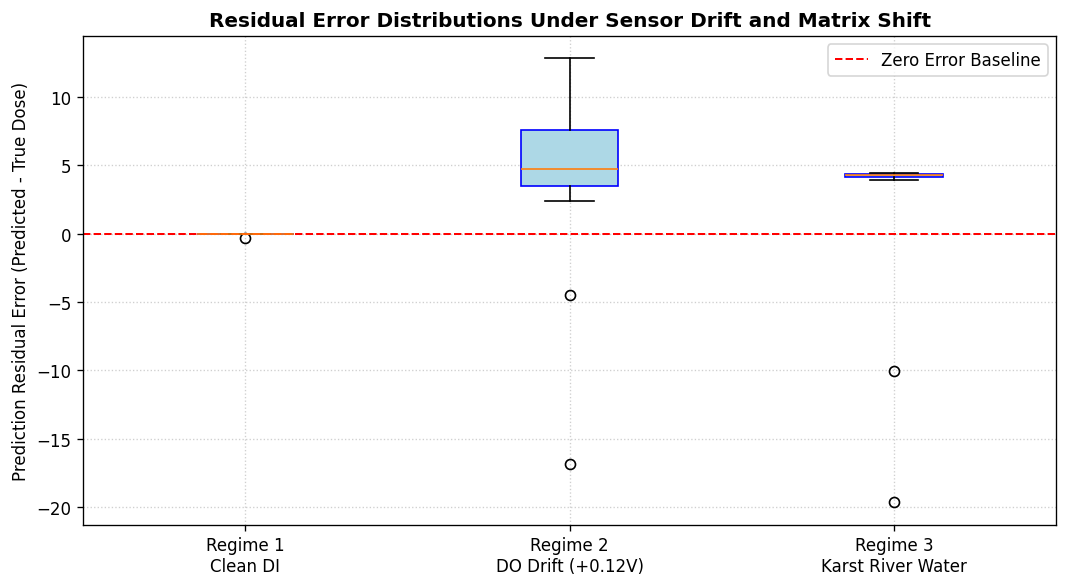

In [2]:
# Generate test dataset (held-out simulation)
np.random.seed(105)
test_df = df_train.sample(25, random_state=105).copy()

# Regime 1: Clean Baseline (No drift)
X7_test1 = scaler_7.transform(test_df[features_7].values)
preds1_cls = clf_7.predict(X7_test1)
oh1 = np.zeros((len(test_df), 5))
for idx, c in enumerate(preds1_cls):
    oh1[idx, classes_5.index(c)] = 1.0
preds1_dose = reg_7.predict(np.hstack([X7_test1, oh1]))
res1 = preds1_dose - test_df['Dose'].values

# Regime 2: Uncorrected Hardware Aeration Drift (+0.12V on DO sensor)
df_regime2 = test_df.copy()
df_regime2['DO'] = df_regime2['DO'] + 0.12
df_regime2['ratio_TDS_DO'] = df_regime2['TDS'] / df_regime2['DO']
X7_test2 = scaler_7.transform(df_regime2[features_7].values)
preds2_cls = clf_7.predict(X7_test2)
oh2 = np.zeros((len(test_df), 5))
for idx, c in enumerate(preds2_cls):
    oh2[idx, classes_5.index(c)] = 1.0
preds2_dose = reg_7.predict(np.hstack([X7_test2, oh2]))
res2 = preds2_dose - test_df['Dose'].values

# Regime 3: Chemically Buffered Karst River Water (Alkalinity shifts pH +5.2, flattens response)
df_regime3 = test_df.copy()
df_regime3['pH'] = df_regime3['pH'] + 5.20
df_regime3['TDS'] = df_regime3['TDS'] + 0.45
df_regime3['ratio_pH_TDS'] = df_regime3['pH'] / df_regime3['TDS']
df_regime3['ratio_TDS_DO'] = df_regime3['TDS'] / df_regime3['DO']
X7_test3 = scaler_7.transform(df_regime3[features_7].values)
preds3_cls = clf_7.predict(X7_test3)
oh3 = np.zeros((len(test_df), 5))
for idx, c in enumerate(preds3_cls):
    oh3[idx, classes_5.index(c)] = 1.0
preds3_dose = reg_7.predict(np.hstack([X7_test3, oh3]))
res3 = preds3_dose - test_df['Dose'].values

table_res = [
    {'Operational Regime': 'Regime 1: Clean Baseline (Pure DI)', 'Mean Error (Bias)': round(np.mean(res1), 4), 'Error Std Dev': round(np.std(res1), 4), 'Max Absolute Error': round(np.max(np.abs(res1)), 4), 'Regression R2': round(r2_score(test_df['Dose'], preds1_dose), 4)},
    {'Operational Regime': 'Regime 2: Hardware DO Aeration Drift (+0.12V)', 'Mean Error (Bias)': round(np.mean(res2), 4), 'Error Std Dev': round(np.std(res2), 4), 'Max Absolute Error': round(np.max(np.abs(res2)), 4), 'Regression R2': round(r2_score(test_df['Dose'], preds2_dose), 4)},
    {'Operational Regime': 'Regime 3: Chemically Buffered Karst River Water', 'Mean Error (Bias)': round(np.mean(res3), 4), 'Error Std Dev': round(np.std(res3), 4), 'Max Absolute Error': round(np.max(np.abs(res3)), 4), 'Regression R2': round(r2_score(test_df['Dose'], preds3_dose), 4)}
]

print('=== PART 2: RESIDUAL ERROR STATISTICS ACROSS OPERATIONAL REGIMES ===')
print(pd.DataFrame(table_res).to_string(index=False))

# Generate Comparative Boxplot
plt.figure(figsize=(9, 5), dpi=120)
plt.boxplot([res1, res2, res3], labels=['Regime 1\nClean DI', 'Regime 2\nDO Drift (+0.12V)', 'Regime 3\nKarst River Water'], patch_artist=True, boxprops=dict(facecolor='lightblue', color='blue'))
plt.axhline(0, color='red', linestyle='--', linewidth=1.2, label='Zero Error Baseline')
plt.ylabel('Prediction Residual Error (Predicted - True Dose)', fontsize=10)
plt.title('Residual Error Distributions Under Sensor Drift and Matrix Shift', fontsize=12, fontweight='bold')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

---
## STEP 3 (Part 3): Model Confidence Auditing & Uncertainty Gating
**Action:** Click the **Play button (▶)** below. This evaluates the SVM probability confidence when presented with clean samples vs. mixtures and hardware drift.

In [3]:
conf_samples = [
    {'Condition': 'Clean Pure Chemical', 'Sample Description': 'Pure NaCl (0.15g)', 'True Target': 'Sodium Chloride', 'pH': 2.37, 'TDS': 0.130, 'Turbidity': 0.002, 'DO': 0.252},
    {'Condition': 'Clean Pure Chemical', 'Sample Description': 'Pure CaCO3 (0.30g)', 'True Target': 'Calcium Carbonate', 'pH': 2.25, 'TDS': 0.040, 'Turbidity': 1.480, 'DO': 0.248},
    {'Condition': 'Drifted Sensor Channel', 'Sample Description': 'Pure NaCl with Aerated DO (0.38V)', 'True Target': 'Sodium Chloride', 'pH': 2.37, 'TDS': 0.130, 'Turbidity': 0.002, 'DO': 0.380},
    {'Condition': 'Binary Mixture (Masked)', 'Sample Description': 'H2O2 (26mL) + CaCO3 (0.21g)', 'True Target': 'H2O2 + CaCO3', 'pH': 2.106, 'TDS': 0.057, 'Turbidity': 0.003, 'DO': 0.260},
    {'Condition': 'Binary Mixture (Confused)', 'Sample Description': 'Mg (0.021g) + NaCl (0.065g)', 'True Target': 'Mg + NaCl', 'pH': 2.797, 'TDS': 0.029, 'Turbidity': 0.001, 'DO': 0.250}
]

df_conf = pd.DataFrame(conf_samples)
df_conf['log_turbidity'] = np.log(1.0 + df_conf['Turbidity'])
df_conf['ratio_pH_TDS']  = df_conf['pH'] / df_conf['TDS']
df_conf['ratio_TDS_DO']  = df_conf['TDS'] / df_conf['DO']

X_conf_scaled = scaler_7.transform(df_conf[features_7].values)
conf_preds = clf_7.predict(X_conf_scaled)
conf_probs = np.max(clf_7.predict_proba(X_conf_scaled), axis=1)

res_conf = []
for i, row in df_conf.iterrows():
    res_conf.append({
        'Operational Condition': row['Condition'],
        'Tested Sample': row['Sample Description'],
        'Single-Label Prediction': conf_preds[i],
        'Model Confidence': f'{conf_probs[i]*100:.1f}%',
        'Gating Action': 'Accept Prediction' if conf_probs[i] >= 0.80 and row['Condition']=='Clean Pure Chemical' else ('REJECT: Suspect Mixture/Drift' if conf_probs[i] < 0.60 else 'FALSE CERTAINTY (Masked)')
    })

print('=== PART 3: MODEL CONFIDENCE AUDIT & UNCERTAINTY GATING ===')
print(pd.DataFrame(res_conf).to_string(index=False))

=== PART 3: MODEL CONFIDENCE AUDIT & UNCERTAINTY GATING ===
    Operational Condition                     Tested Sample Single-Label Prediction Model Confidence                 Gating Action
      Clean Pure Chemical                 Pure NaCl (0.15g)         Sodium Chloride            84.9%             Accept Prediction
      Clean Pure Chemical                Pure CaCO3 (0.30g)       Calcium Carbonate            80.1%             Accept Prediction
   Drifted Sensor Channel Pure NaCl with Aerated DO (0.38V)       Hydrogen Peroxide            42.0% REJECT: Suspect Mixture/Drift
  Binary Mixture (Masked)       H2O2 (26mL) + CaCO3 (0.21g)         Sodium Chloride            96.2%      FALSE CERTAINTY (Masked)
Binary Mixture (Confused)       Mg (0.021g) + NaCl (0.065g)      Sodium Bicarbonate            80.1%      FALSE CERTAINTY (Masked)


---
## STEP 4 (Part 5): Streeter-Phelps Dissolved Oxygen Sag Curve Simulation
**Action:** Click the **Play button (▶)** below to plot the official NCEES FE Reference Handbook Streeter-Phelps Dissolved Oxygen Sag Curve.

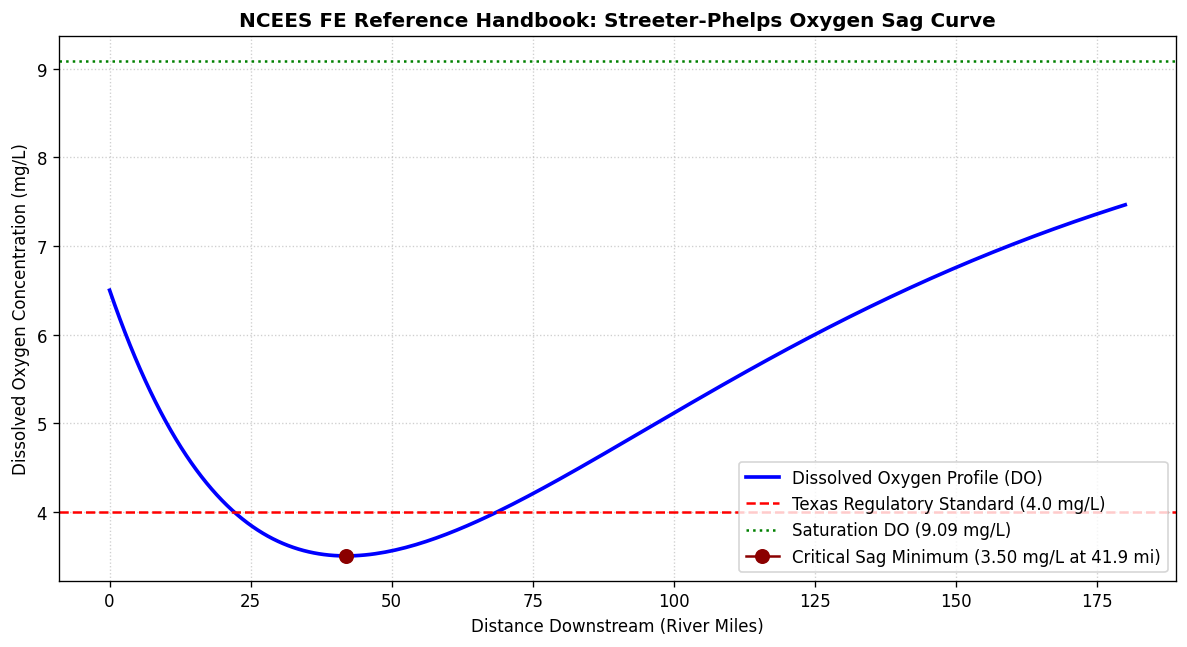

Critical Travel Time (t_c): 2.327 days
Critical Downstream Distance (x_c): 41.89 miles
Critical Oxygen Deficit (D_c): 5.59 mg/L
Minimum River DO (DO_min): 3.50 mg/L


In [4]:
# Streeter-Phelps Dissolved Oxygen Sag Modeling (NCEES FE Reference Handbook Parameters)
# Parameters from Part 5:
DO_sat = 9.09   # mg/L at 20 deg C
DO_0   = 6.50   # mg/L
D_0    = DO_sat - DO_0  # Initial deficit = 2.59 mg/L
L_0    = 18.0   # mg/L ultimate BOD
k_d    = 0.25   # day^-1
k_r    = 0.45   # day^-1
u      = 18.0   # miles/day

t = np.linspace(0, 10, 200) # days
x = u * t                   # river miles downstream

# Streeter-Phelps Equation from FE Reference Handbook:
# D(t) = [k_d * L_0 / (k_r - k_d)] * [exp(-k_d * t) - exp(-k_r * t)] + D_0 * exp(-k_r * t)
D_t = (k_d * L_0 / (k_r - k_d)) * (np.exp(-k_d * t) - np.exp(-k_r * t)) + D_0 * np.exp(-k_r * t)
DO_t = DO_sat - D_t

# Critical values:
t_c = (1.0 / (k_r - k_d)) * np.log((k_r / k_d) * (1.0 - D_0 * (k_r - k_d) / (k_d * L_0)))
x_c = u * t_c
D_c = (k_d / k_r) * L_0 * np.exp(-k_d * t_c)
DO_min = DO_sat - D_c

plt.figure(figsize=(10, 5.5), dpi=120)
plt.plot(x, DO_t, color='blue', linewidth=2.2, label='Dissolved Oxygen Profile (DO)')
plt.axhline(4.0, color='red', linestyle='--', linewidth=1.5, label='Texas Regulatory Standard (4.0 mg/L)')
plt.axhline(DO_sat, color='green', linestyle=':', label=f'Saturation DO ({DO_sat} mg/L)')
plt.plot(x_c, DO_min, marker='o', markersize=8, color='darkred', label=f'Critical Sag Minimum ({DO_min:.2f} mg/L at {x_c:.1f} mi)')

plt.xlabel('Distance Downstream (River Miles)', fontsize=10)
plt.ylabel('Dissolved Oxygen Concentration (mg/L)', fontsize=10)
plt.title('NCEES FE Reference Handbook: Streeter-Phelps Oxygen Sag Curve', fontsize=12, fontweight='bold')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

print(f'Critical Travel Time (t_c): {t_c:.3f} days')
print(f'Critical Downstream Distance (x_c): {x_c:.2f} miles')
print(f'Critical Oxygen Deficit (D_c): {D_c:.2f} mg/L')
print(f'Minimum River DO (DO_min): {DO_min:.2f} mg/L')